In [1]:
import pandas as pd
df = pd.read_csv(r"C:\Users\sharm\OneDrive\Documents\Black Friday Data.csv1.csv")

In [2]:
df.head(5)

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,NaN,NaN,8370
1,1000001,P00248942,F,0-17,10,A,2,0,1,6.0,14.0,15200
2,1000001,P00087842,F,0-17,10,A,2,0,12,NaN,NaN,1422
3,1000001,P00085442,F,0-17,10,A,2,0,12,14.0,NaN,1057
4,1000002,P00285442,M,55+,16,C,4+,0,8,NaN,NaN,7969


In [3]:
df.isnull().sum()

User_ID                            0
Product_ID                         0
Gender                             0
Age                                0
Occupation                         0
City_Category                      0
Stay_In_Current_City_Years         0
Marital_Status                     0
Product_Category_1                 0
Product_Category_2            173638
Product_Category_3            383247
Purchase                           0
dtype: int64

In [4]:
df.describe()

,User_ID,Occupation,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
count,5.500680e+05,550068.000000,550068.000000,550068.000000,376430.000000,166821.000000,550068.000000
mean,1.003029e+06,8.076707,0.409653,5.404270,9.842329,12.668243,9263.968713
std,1.727592e+03,6.522660,0.491770,3.936211,5.086590,4.125338,5023.065394
min,1.000001e+06,0.000000,0.000000,1.000000,2.000000,3.000000,12.000000
25%,1.001516e+06,2.000000,0.000000,1.000000,5.000000,9.000000,5823.000000
50%,1.003077e+06,7.000000,0.000000,5.000000,9.000000,14.000000,8047.000000
75%,1.004478e+06,14.000000,1.000000,8.000000,15.000000,16.000000,12054.000000
max,1.006040e+06,20.000000,1.000000,20.000000,18.000000,18.000000,23961.000000


In [5]:
df['Product_Category_2'] = df['Product_Category_2'].fillna(0)
df['Product_Category_3'] = df['Product_Category_3'].fillna(0)

In [6]:
df.isnull().sum()

User_ID                       0
Product_ID                    0
Gender                        0
Age                           0
Occupation                    0
City_Category                 0
Stay_In_Current_City_Years    0
Marital_Status                0
Product_Category_1            0
Product_Category_2            0
Product_Category_3            0
Purchase                      0
dtype: int64

# Gender Wise Sales

In [7]:
Gender_sales = df.groupby('Gender')['Purchase'].sum()
print(Gender_sales)

Gender
F    1186232642
M    3909580100
Name: Purchase, dtype: int64


# Male shoppers drove the vast majority of total purchasing volume contribute over 3.90 billion dollars. whereas female shoppers contribute total purchase volume of approximately 1.18 billion dollars.

# Category Wise Sales

In [8]:
Category_sales = df.groupby('Product_Category_1')['Purchase'].sum().sort_values(ascending=False)
print(Category_sales)                         

Product_Category_1
1     1910013754
5      941835229
8      854318799
6      324150302
2      268516186
3      204084713
16     145120612
11     113791115
10     100837301
15      92969042
7       60896731
4       27380488
14      20014696
18       9290201
9        6370324
17       5878699
12       5331844
13       4008601
20        944727
19         59378
Name: Purchase, dtype: int64


# Category 1 is the highest revenue generator by wide margin,pulling purchase of volume of over 1.91 billion. The other following categories are categories 5 and 8 follow strong revenue respectively. categories like 19,20 and 13 are the leasr impact categories in dataset.

# Age Wise Sales

In [9]:
Age_sales = df.groupby('Age')['Purchase'].sum()
print(Age_sales)

Age
0-17      134913183
18-25     913848675
26-35    2031770578
36-45    1026569884
46-50     420843403
51-55     367099644
55+       200767375
Name: Purchase, dtype: int64


# 26-35 Age bracket people were pulling over 2.03 billion dollar puchases.

# 36-45 Age bracket people were pulling over 1.02 billion dollar purchase. the age between 25 to 50 is working age so its obvious they generate more revenue.

# Young buyers 18-25 spent around 913 milion dollars. whereas the older segment above 55+ and 0-17 contributed ower volumes among all of them.

# City Wise Sales

In [10]:
City_sales = df.groupby('City_Category')['Purchase'].sum().sort_values(ascending=False)
print(City_sales)

City_Category
B    2115533605
C    1663807476
A    1316471661
Name: Purchase, dtype: int64


# City_Category B leads in all of them pulling over 2.11 billion total purchases.City_Category C right behind with over 1.66 billion and the City_Category A generate the lowest revenue of 1.31 billion among all.


# Marital Sales Status

In [11]:
Marital_Status = df.groupby('Marital_Status')['Purchase'].sum()
print(Marital_Status)

Marital_Status
0    3008927447
1    2086885295
Name: Purchase, dtype: int64


# Unmarried shoppers pulling over 3 billion dollar revenue.whereas the Married Shoppers contributed over 2.08 billion dollars revenue.

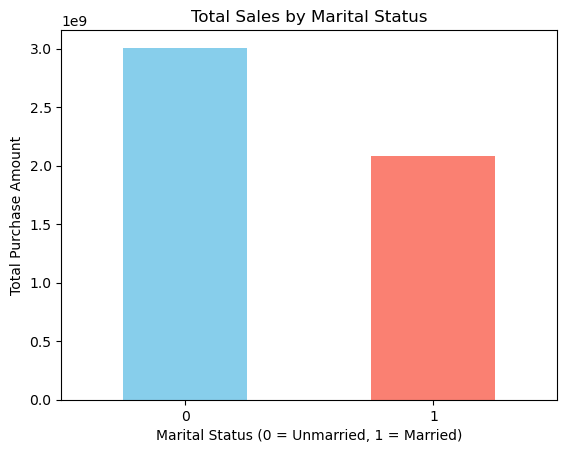

In [12]:
import matplotlib.pyplot as plt

#  Marital Status Sales
Marital_Status.plot(kind='bar', color=['skyblue', 'salmon'])
plt.title('Total Sales by Marital Status')
plt.xlabel('Marital Status (0 = Unmarried, 1 = Married)')
plt.ylabel('Total Purchase Amount')
plt.xticks(rotation=0)
plt.show()

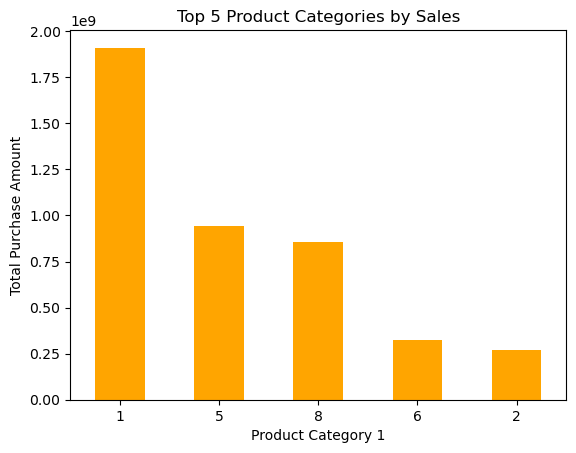

In [13]:
#  Top Product Categories
Category_sales.head(5).plot(kind='bar', color='orange')
plt.title('Top 5 Product Categories by Sales')
plt.xlabel('Product Category 1')
plt.ylabel('Total Purchase Amount')
plt.xticks(rotation=0)
plt.show()

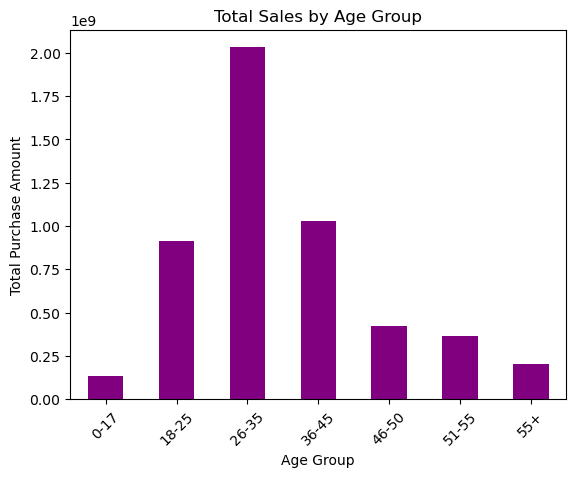

In [14]:
#  Sales by Age Group
Age_sales.plot(kind='bar', color='purple')
plt.title('Total Sales by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Total Purchase Amount')
plt.xticks(rotation=45)
plt.show()

In [15]:
from scipy import stats

# 1. Separate the purchase data by gender
male_purchases = df[df['Gender'] == 'M']['Purchase']
female_purchases = df[df['Gender'] == 'F']['Purchase']

# 2. Run the independent t-test
t_stat, p_value = stats.ttest_ind(male_purchases, female_purchases, equal_var=False)

print(f"T-Statistic: {t_stat}")
print(f"P-Value: {p_value}")

T-Statistic: 46.35824866962607
P-Value: 0.0


In [16]:
df.to_csv('black_friday_cleaned.csv',index=False)
print('Cleaned dataset successfully exported')

Cleaned dataset successfully exported


In [17]:
from scipy import stats

# 1. T-Test: Compare spending between Genders
male_purchases = df[df['Gender'] == 'M']['Purchase']
female_purchases = df[df['Gender'] == 'F']['Purchase']

t_stat, p_value = stats.ttest_ind(male_purchases, female_purchases, equal_var=False)
print("--- T-Test: Gender vs Purchase Amount ---")
print(f"T-Statistic: {t_stat:.4f}")
print(f"P-Value: {p_value:.4e}\n")

# 2. ANOVA Test: Compare spending across City Categories
city_groups = [group['Purchase'].values for name, group in df.groupby('City_Category')]
f_stat, anova_p = stats.f_oneway(*city_groups)
print("--- ANOVA Test: City Categories vs Purchase Amount ---")
print(f"F-Statistic: {f_stat:.4f}")
print(f"P-Value: {anova_p:.4e}")

--- T-Test: Gender vs Purchase Amount ---
T-Statistic: 46.3582
P-Value: 0.0000e+00

--- ANOVA Test: City Categories vs Purchase Amount ---
F-Statistic: 1130.7460
P-Value: 0.0000e+00


# 📊 Black Friday Sales Analysis: Comprehensive End-to-End Report

## 📋 1. Project Overview & Business Objective
* **Project Scope:** Comprehensive analysis of over 550,000 retail transactions from a nationwide Black Friday sales campaign to decode consumer purchasing behavior.
* **Primary Objective:** Transform raw, unstructured retail data into actionable business intelligence by cleaning data anomalies, exploring core trends, and validating behavioral assumptions using rigorous statistical hypothesis testing.

## 🧹 2. Data Wrangling & Hygiene
* **Dataset Scale:** Successfully ingested and processed a large-scale transactional dataset comprising 550k+ rows and multiple categorical and numerical attributes.
* **Missing Value Management:** Identified and systematically resolved data gaps within secondary and tertiary product categories (`Product_Category_2` and `Product_Category_3`) to maintain structural integrity across the relational layout.
* **Export & Pipeline Validation:** Validated the cleaned dataset and successfully exported it (`black_friday_cleaned.csv`) to establish a standardized baseline for all downstream analysis.

## 🔍 3. Exploratory Data Analysis (EDA) & Descriptive Statistics
* **Distribution & Trend Reports:** Analyzed purchase amount distributions, product category frequencies, and overall revenue contributions at the city level.
* **Demographic Breakdown:** Explored high-spending customer segments grouped by age, gender, occupation, and marital status to identify core revenue drivers.
* **Outlier Detection:** Summarized category-level contributions and detected spending anomalies to understand skewness in retail purchase behavior prior to formal statistical testing.

## 📈 4. Inferential Statistics & Hypothesis Testing
* **Gender Spending Impact (Independent Two-Sample T-Test):**
  * **Objective:** Evaluate whether transaction purchase amounts differ significantly between male and female shoppers.
  * **Statistical Results:** Yielded a high T-Statistic of approximately ~46.36 and a $p$-value of `0.0`.
  * **Business Insight:** Completely rejected the null hypothesis, confirming a statistically significant variance in spending behavior across genders.
* **Geographic Variations (One-Way ANOVA Test):**
  * **Objective:** Assess whether customer purchasing power changes significantly across different city tiers (City Categories A, B, and C).
  * **Statistical Results:** Evaluated grouped variance across all three municipal classifications.
  * **Business Insight:** Scientifically verified the impact of geographic location on sales volume, providing concrete validation for regional inventory stocking and location-based marketing campaigns.